**NOTE: Please use the tree image saved in the folder module 5. We are explaining everything using that image only.**

## Importing the required libraries

In [1]:
#Importing libraries
import pandas as pd
import numpy as np
import os

## Read and display the sample dataset

In [2]:
os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module5')
data = pd.read_csv("synergix_sample_data.csv")
data.head(30)

,Segment,Num_of_Promotions,Units_sold>1000
0,1,0.0,0
1,0,0.0,0
2,2,0.0,0
3,2,0.0,0
4,2,0.0,0
5,1,0.0,0
6,1,0.0,0
7,2,0.0,0
8,2,0.0,0
9,1,0.0,0


In [3]:
data.shape

(30, 3)

## Creating dependent and independent variables

In [4]:
# Features
X = data.drop(labels = ['Units_sold>1000'],axis=1)

#Target variable
y = data ['Units_sold>1000']


## Model building

In [5]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree model
DT_model = DecisionTreeClassifier(criterion = 'gini',  random_state = 42)

"""
Gini measures how "mixed" a node is.
- gini = 0 -> pure node

Note:  The tree always tries to find the split that reduces Gini the most.
"""

# Train the model
DT_model.fit(X,y)
"""

"""

'\n\n'

## Tree visualization

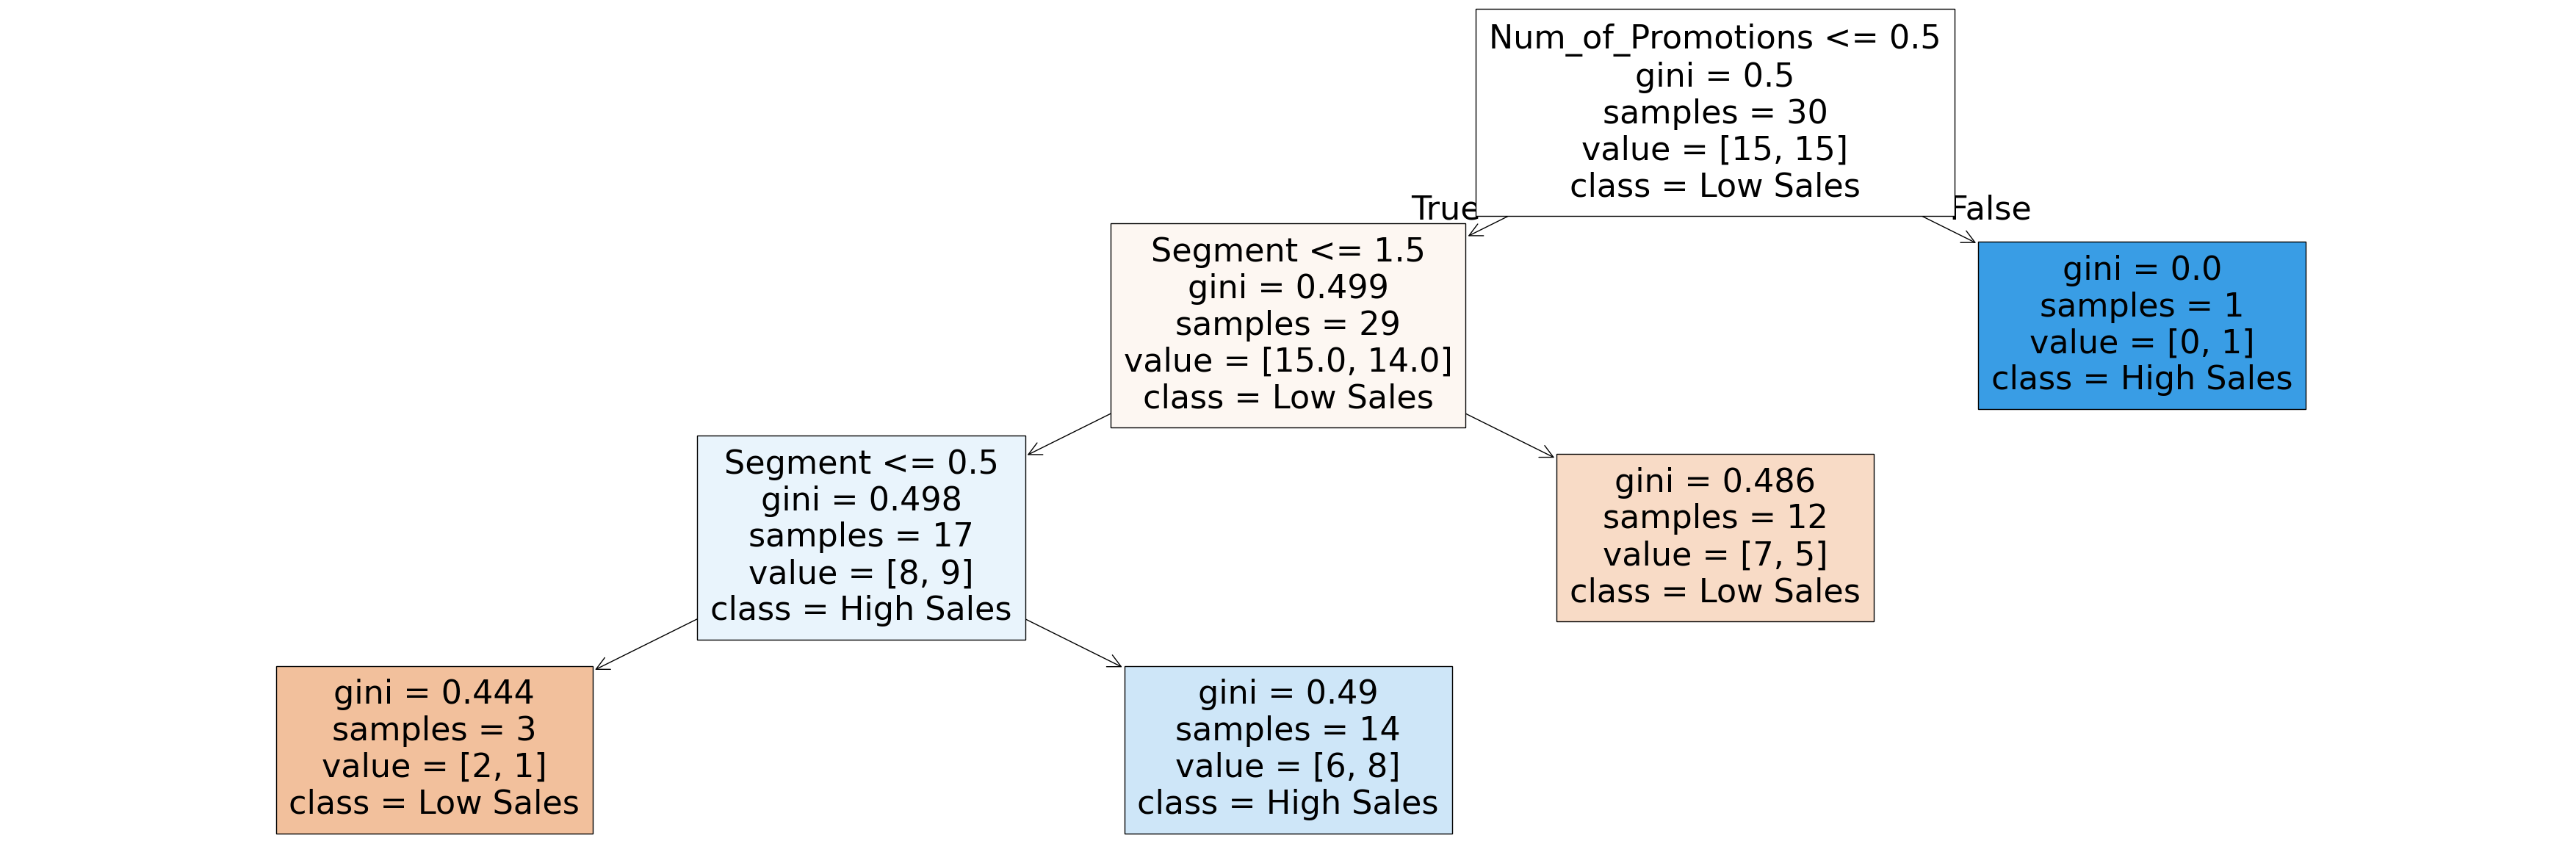

In [6]:
from matplotlib import pyplot as plt

# Visualizing the decision tree
from sklearn import tree
fig = plt.figure(figsize=(45,15))
features = X.columns
_ = tree.plot_tree(DT_model, 
                   feature_names=features,  
                   class_names=['Low Sales', 'High Sales'],
                   filled=True)


---

![Image Description](DIKHSITATREE.png)

##### Flow so Far

**Load data → Split X/y → Train tree → Visualize**

## Math Behind Why the Tree Split


##### Defining function to calculate the Gini Impurity

In [7]:
# Function that calculates the Gini Impurity and returns the value rounded to three decimal places

def gini(num_Class_0, num_Class_1):
    p_class_0 = num_Class_0/(num_Class_0+num_Class_1)
    p_class_1 = num_Class_1/(num_Class_0+num_Class_1)
    gini = 1-(p_class_0**2 + p_class_1**2)
    return np.round(gini, 3)

#### Gini Impurity of root node

In [19]:
gini_root = gini(15,15)
gini_root

np.float64(0.5)

#### Gini Impurity of child nodes

In [9]:
gini_child_node1 = gini(10,14)
gini_child_node1

np.float64(0.486)

In [10]:
gini_child_node2 = gini(5,1)
gini_child_node2

np.float64(0.278)

#### Gini Impurity of a leaf node

In [11]:
gini_branch_node1 = gini(2,0)
gini_branch_node1

np.float64(0.0)

#### Calculate the weighted Gini Impurity

**Purpose**: Compute a single number that represents the combined impurity of both child nodes after the split — taking into account that the two child nodes are different sizes.

In [12]:
# Calculate the weighted Gini Impurity
weighted_Gini = ((24/30) * (0.486)) + ((6/30)*(0.278)) 
np.round(weighted_Gini, 3)

np.float64(0.444)

**What this means**: 
- After the split on *Segment <= 1.5*, the combined impurity of the two child nodes is 0.444. 
- Compare this to the root's Gini of 0.5 — we went from 0.5 down to 0.444. 
- The split made things more pure overall.

#### Gini Gain

**Purpose**
- Measure how much the split actually improved things. 
- This is called Gini Gain (also sometimes called Impurity Reduction).

In [13]:
# GINI ROOT NODE - WEIGHTED GINI OF BRANCH NODES
0.5 - 0.444

0.055999999999999994

**What this means**: By splitting on *Segment <= 1.5*, the tree reduced overall impurity by **0.056**.

**This is how the tree decides which feature to split on**. 
- Internally, before building the tree, sklearn computes this Gini Gain for every possible split on every feature, then picks the one with the highest gain. 
- In this case, splitting on Segment at threshold 1.5 gave the best gain, which is why it became the root split.